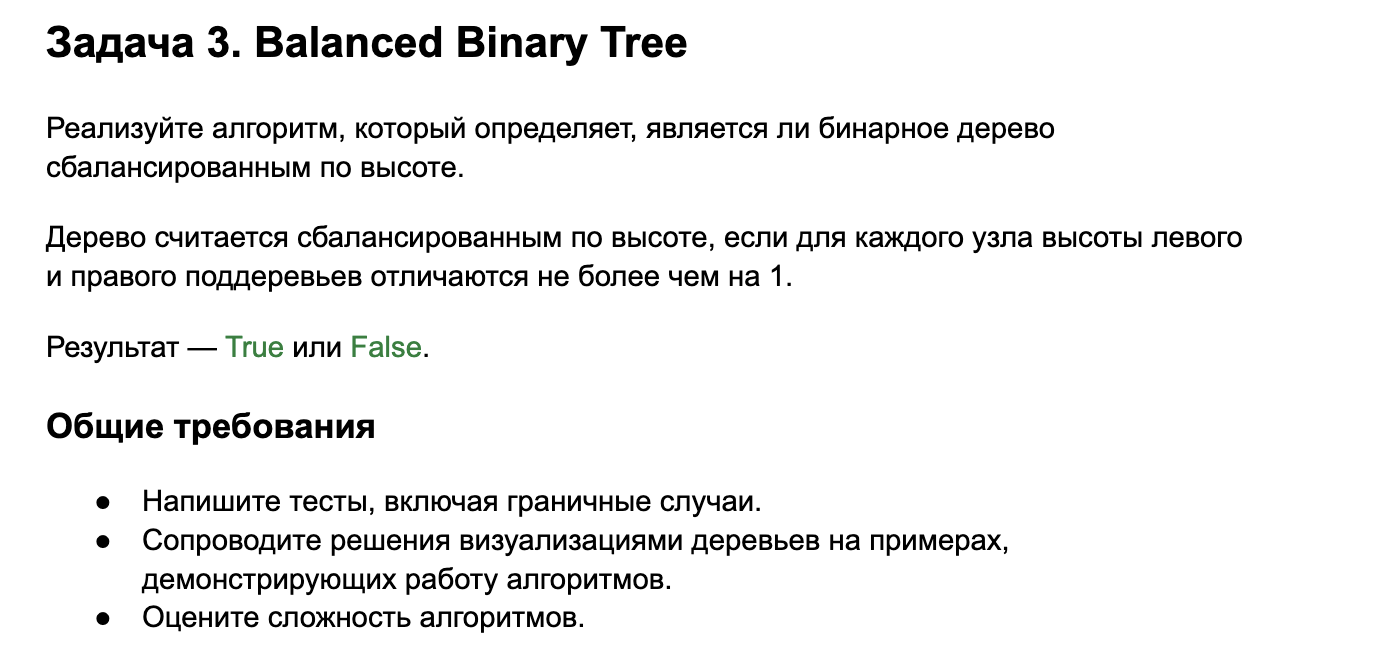

## Ход решения

Бинарное дерево сбалансировано, если для **каждой вершины** высоты её левого и правого поддеревьев отличаются не более чем на `1`:

$$
|h_{left} - h_{right}| \leq 1.
$$

Для решения будем использовать LRN (postorder) - то есть обход в глубину: сначала обходим левое поддерево (Left), затем правое (Right) и только после этого обрабатываем текущую вершину (Node).

Такой порядок удобен, поскольку для проверки баланса текущей вершины нам сначала нужно узнать высоты обоих её поддеревьев, и потом перейти к вершине, если все нормик.

Будем считать, что высота пустого дерева равна `0`, а высота листа — `1`.

Реализуем рекурсивную функцию `dfs(node)`, которая возвращает:

- **Высоту поддерева**, если оно сбалансировано.
- `-1`, если в поддереве обнаружен дисбаланс.

Значение `-1` используем как специальный сигнал. Если хотя бы одно поддерево несбалансировано, проверять остальные вершины уже не нужно: всё дерево в любом случае будет несбалансированным. Поэтому передаём `-1` вверх по рекурсивным вызовам, пока он не дойдёт до корня.

**Работа алгоритма:**

1. **Проверяем базовый случай.** Если `node is None`, возвращаем `0`, поскольку высота пустого дерева равна нулю.
2. **Вычисляем высоту левого поддерева:** `left_height = dfs(node.left)`. Рекурсивно спускаемся до листьев, после чего начинаем возвращаться вверх, вычисляя высоты. Если получили `-1`, значит, слева уже обнаружен дисбаланс, то мы сразу возвращаем `-1`, не проверяя правое поддерево.
3. **Вычисляем высоту правого поддерева:** `right_height = dfs(node.right)`. Делаем то же самое для правой части. Если получили `-1`, также сразу возвращаем `-1`.
4. **Проверяем баланс текущей вершины.** Если `abs(left_height - right_height) > 1`, значит, разница высот превышает допустимую. Возвращаем `-1`.
5. **Вычисляем высоту текущего поддерева.** Если оба поддерева сбалансированы и разница их высот не превышает `1`, возвращаем `1 + max(left_height, right_height)`. Единицу добавляем, потому что мы находимся в текущей вершин, которая еще не посчитана, а максимум берём потому, что высота дерева определяется его самой длинной веткой, и нужно знать ее длину.

Таким образом, **высоты вычисляются снизу вверх**, и каждая вершина проверяется только после своих детей. Если на каком-либо этапе обнаруживается дисбаланс, `-1` последовательно передаётся наверх, позволяя не обходить оставшиеся ветви.

В результате дерево сбалансировано тогда и только тогда, когда `dfs(root) != -1`.

## Сложность алгоритма

Пусть `n` — количество вершин, `h` — высота дерева.

| Ресурс | Сложность | Почему |
| --- | --- | --- |
| Время | **`O(n)`** | Каждая вершина посещается не более одного раза. |
| Дополнительная память | **`O(h)`** | Хранятся только вызовы рекурсии вдоль текущего пути. |

Для сбалансированного дерева `h = O(log n)`, для вырожденного дерева в худшем случае `h = O(n)`. Список высот для всех узлов не создаём.

# Реализация

Сначала реализуем вершину дерева: значение `value` и ссылки `left` / `right`. Конструктор также позволяет удобно собирать деревья для тестов.

In [1]:
class Node:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

### Проверка сбалансированности

`dfs` возвращает высоту поддерева либо `-1`, если оно несбалансировано.

In [2]:
def is_balanced(root):
    def dfs(node):
        if node is None:
            return 0

        left_height = dfs(node.left)
        if left_height == -1:
            return -1

        right_height = dfs(node.right)
        if right_height == -1:
            return -1

        if abs(left_height - right_height) > 1:
            return -1

        return 1 + max(left_height, right_height)

    return dfs(root) != -1

# Визуализация работы алгоритма

Рассмотрим **несбалансированное дерево**:

```text
                 10
               /    \
              5      15
             / \       \
            3   7       20
           /             \
          1               25
                            \
                             30
```

DFS сначала полностью проверяет левое поддерево, затем — правое. **Высоты вычисляются снизу вверх**, поэтому листья возвращают `1`, а их родители получают уже вычисленные высоты. Более того, поскольку мы реализовали postorder, то начинаем с левого поддерва.

| Шаг | Вершина | Высота слева | Высота справа | Разница | Что возвращаем |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 1 | 1 | 0 | 0 | 0 | `1` |
| 2 | 3 | 1 | 0 | 1 | `2` |
| 3 | 7 | 0 | 0 | 0 | `1` |
| 4 | 5 | 2 | 1 | 1 | `3` |
| 5 | 30 | 0 | 0 | 0 | `1` |
| 6 | 25 | 0 | 1 | 1 | `2` |
| **7** | **20** | **0** | **2** | **2** | **`-1`** |
| 8 | 15 | — | — | — | `-1` |
| 9 | 10 | — | — | — | `-1` |

Критический участок:

```text
20
  \
   25
     \
      30
```

Для вершины `20` получаем `|0 - 2| = 2 > 1`. Значит, `dfs(20)` возвращает `-1`. Узлы `15` и `10` лишь передают этот сигнал наверх, не вычисляя высоты заново. **Итог: `False`.**

Важно: проверки у `15` и `10` на разницу высот уже не выполняются, потому что их дочернее поддерево вернуло `-1`. В таблице `None`-дети опущены.

### Сравнение: сбалансированное дерево

```text
                 10
               /    \
              5      15
             / \    /  \
            3   7  12  20
```

Высота каждого листа — `1`, высоты поддеревьев у `5` и `15` — `2`, высота корня — `3`. У всех вершин разница высот не больше `1`, поэтому функция возвращает `True`.

In [3]:
unbalanced = Node(
    10,
    Node(5, Node(3, Node(1)), Node(7)),
    Node(15, None, Node(20, None, Node(25, None, Node(30)))),
)

balanced = Node(
    10,
    Node(5, Node(3), Node(7)),
    Node(15, Node(12), Node(20)),
)

print("Несбалансированное дерево:", is_balanced(unbalanced))
print("Сбалансированное дерево:", is_balanced(balanced))

Несбалансированное дерево: False
Сбалансированное дерево: True


# Тесты

Проверим пустое дерево, один и два узла, полное дерево, допустимую разницу высот `1`, нарушения у корня и глубоко внутри дерева, цепочки влево/вправо, отрицательные и повторяющиеся значения. Добавим важный случай: **у корня высоты поддеревьев одинаковые, но одна из внутренних вершин несбалансирована** — проверять только корень недостаточно.

In [4]:
test_cases = [
    ("Пустое дерево", None, True),
    ("Одна вершина", Node(1), True),
    ("Две вершины", Node(1, Node(2)), True),
    ("Два ребёнка", Node(1, Node(2), Node(3)), True),
    ("Полное дерево", balanced, True),
    ("Разница высот = 1", Node(1, Node(2, Node(4)), Node(3)), True),
    ("Разница высот = 2", Node(1, Node(2, Node(3))), False),
    ("Цепочка влево", Node(1, Node(2, Node(3, Node(4)))), False),
    ("Цепочка вправо", Node(1, None, Node(2, None, Node(3, None, Node(4)))), False),
    ("Дисбаланс глубоко в дереве", unbalanced, False),
    (
        "Высоты корня равны, внутри дисбаланс",
        Node(10, Node(5, Node(3, Node(1)), Node(7)), Node(15, None, Node(20, None, Node(25)))),
        False,
    ),
    ("Не BST, но сбалансировано", Node(10, Node(20), Node(5)), True),
    ("Отрицательные значения", Node(-10, Node(-20), Node(-5)), True),
    ("Повторяющиеся значения", Node(5, Node(5), Node(5)), True),
]

for name, root, expected in test_cases:
    actual = is_balanced(root)
    assert actual == expected, f"{name}: ожидалось {expected}, получено {actual}"

print(f"Все {len(test_cases)} тестов пройдены!")

Все 14 тестов пройдены!


### Дополнительная проверка на более крупном дереве

Построим полное дерево высоты `8` (255 вершин). Оно должно быть сбалансировано. Затем добавим к одному крайнему листу цепочку из двух узлов — появится локальный дисбаланс, и ответ станет `False`.

In [5]:
def build_full_tree(height):
    if height == 0:
        return None
    return Node(height, build_full_tree(height - 1), build_full_tree(height - 1))

root = build_full_tree(8)
assert is_balanced(root) is True

node = root
while node.left is not None:
    node = node.left
node.left = Node(1, Node(0))
assert is_balanced(root) is False

print("Проверка большого дерева пройдена!")

Проверка большого дерева пройдена!


**Вывод:** проверка сбалансированности выполняется за один DFS. Возвращая высоту снизу вверх и используя `-1` для сигнала о дисбалансе, получаем решение с `O(n)` по времени и `O(h)` по дополнительной памяти.